# Figure 2: ecDNA circularization junctions versus chromosomal scars

In three tumors the amplified-region boundaries show **two different kinds of junction**: high-copy junctions that close the ecDNA circle, and low-copy junctions left on the chromosome of origin (a chromosomal *scar* of excision). This notebook finds those junctions from HiFi split-read alignments, counts the molecules supporting each, measures how far the scar breakpoints sit from the ecDNA breakpoints (the Δ offsets), and draws every supporting read.

| Tumor | Sample | What is shown |
|---|---|---|
| GBM19 | `UM233` | simple excision scar: ecDNA junction (high count) and a chromosomal deletion junction at offset breakpoints |
| GBM15 | `UM215` | two-segment ecDNA (chr7:23 Mb and chr7:54-55 Mb), with an ~32-Mb chromosomal deletion scar |
| GBM20 | `UM244` | chr7 ecDNA joined to a small chr1 fragment; chr7 scar breakpoints joined to chr1 instead of to each other |

The notebook also contains a plain alignment viewer (`plot_paf`) that draws every alignment of every split read in a locus. Each stacked plot shows the individual reads that support a junction, so the breakpoints can be seen directly at single-molecule level.

**Approach.** HiFi reads from the breakpoint regions are re-aligned with minimap2 to the whole genome and written as PAF. A read that crosses a junction aligns in two (or more) pieces. Joining consecutive pieces of the same read, in read order, gives the junction that molecule carries. Junctions are then counted and reads are classified as ecDNA, scar or reference (unrearranged).

**Limitation.** A rearrangement encoded as one long deletion *inside* a single alignment (a long `D` in the CIGAR) produces no second alignment, so it is not seen by this split-read approach.

## 0. Setup and inputs

Inputs are two PAF files made with the commands in the appendix:

* `UM233_Tumor_chr7_49_59mb.paf.gz` (GBM19)
* `UM215_GBM15_chr7_ecDNA_breakpoints.paf.gz` (GBM15)
* `UM-244_breakpoint_regions.paf.gz` (GBM20)

In [2]:
import gzip
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import display

DATA_DIR = Path("/Users/isaacxu/Downloads/ecDNA/")
OUT = Path("fig2_output")
OUT.mkdir(exist_ok=True)

PAF_GBM19 = DATA_DIR / "UM233_Tumor_chr7_49_59mb.paf.gz"
PAF_GBM15 = DATA_DIR / "UM215_GBM15_chr7_ecDNA_breakpoints.paf.gz"
PAF_GBM20 = DATA_DIR / "UM-244_breakpoint_regions.paf.gz"

## 1. Reading PAF alignments and finding junctions

`read_paf` loads the alignments. `extract_junctions` sorts each read's alignments by position **along the read** and records the genomic coordinate at the end of one piece and the start of the next. `summarize_junctions` counts reads per junction (coordinates binned to `bin_bp`; junction ends are order-independent).

In [3]:
PAF_CORE = ["qname","qlen","qstart","qend","strand","tname","tlen","tstart","tend","nmatch","alen","mapq"]

def read_paf(path, keep_tags=("tp","dv","s1","cm")):
    opener = gzip.open if str(path).endswith(".gz") else open
    rows = []
    with opener(path, "rt") as f:
        for line in f:
            if not line.strip():
                continue
            parts = line.rstrip("\n").split("\t")
            d = dict(zip(PAF_CORE, parts[:12]))
            for k in ("qlen","qstart","qend","tlen","tstart","tend","nmatch","alen","mapq"):
                d[k] = int(d[k])
            for tag in parts[12:]:
                try:
                    name, typ, val = tag.split(":", 2)
                except ValueError:
                    continue
                if name in keep_tags:
                    d[name] = int(val) if typ == "i" else float(val) if typ == "f" else val
            rows.append(d)
    df = pd.DataFrame(rows)
    df["mapq"] = pd.to_numeric(df["mapq"], errors="coerce").fillna(0).astype(int)
    return df

def extract_junctions(df, min_mapq=0, same_chrom_only=True):
    """For every read, join consecutive alignments (in read order) into junctions."""
    d = df[df["mapq"] >= min_mapq].copy()
    for c in ["tstart","tend","qstart","qend"]:
        d[c] = pd.to_numeric(d[c], errors="coerce")
    d = d.dropna(subset=["qname","tname","tstart","tend","qstart","qend"]).sort_values(["qname","qstart","qend"])
    rows = []
    for rid, g in d.groupby("qname", sort=False):
        if len(g) < 2:
            continue
        segs = g.to_dict("records")
        for a, b in zip(segs[:-1], segs[1:]):
            if same_chrom_only and a["tname"] != b["tname"]:
                continue
            pos1 = int(a["tend"]) if a["strand"] == "+" else int(a["tstart"])
            pos2 = int(b["tstart"]) if b["strand"] == "+" else int(b["tend"])
            rows.append({"read_id": rid, "chr1": a["tname"], "pos1": pos1, "strand1": a["strand"],
                         "chr2": b["tname"], "pos2": pos2, "strand2": b["strand"]})
    return pd.DataFrame(rows)

def summarize_junctions(junc_df, min_support=2, bin_bp=50):
    """Count reads per junction (both ends binned to bin_bp, order-independent)."""
    d = junc_df.copy()
    if d.empty:
        return d
    d["p1"] = (d["pos1"] // bin_bp) * bin_bp
    d["p2"] = (d["pos2"] // bin_bp) * bin_bp
    chrA, posA, chrB, posB = [], [], [], []
    for a, b in zip(zip(d["chr1"], d["p1"]), zip(d["chr2"], d["p2"])):
        lo, hi = (a, b) if a <= b else (b, a)
        chrA.append(lo[0]); posA.append(lo[1]); chrB.append(hi[0]); posB.append(hi[1])
    d["chrA"], d["posA"], d["chrB"], d["posB"] = chrA, posA, chrB, posB
    out = d.groupby(["chrA","posA","chrB","posB"]).size().reset_index(name="support").sort_values("support", ascending=False)
    return out[out["support"] >= min_support].copy()

## 2. GBM15

### 2.1 Junctions discovered in the PAF

All junctions with support of at least 3 reads, from alignments with mapping quality of at least 50 and at least two alignments per read. The ecDNA junctions are the high-count ones; the chromosomal scar junction has far fewer reads. This table bins junctions at exactly 1 bp, so molecules whose breakpoints differ by a few bp are split across neighbouring rows and low-count junctions such as the scar are under-counted here. The viewer below pools reads whose breakpoints lie within `tol` = 200 bp of the junction coordinates; those pooled molecule counts are the ones reported.

In [4]:
paf15 = read_paf(PAF_GBM15)
print(f"Loaded {len(paf15):,} alignments, {paf15['qname'].nunique():,} reads")

hq = paf15[paf15["mapq"] > 50].reset_index(drop=True)
split = hq[hq.groupby("qname")["qname"].transform("count") > 1]
print(f"Split reads (mapq > 50): {split['qname'].nunique():,}")

junc15 = extract_junctions(split, min_mapq=20, same_chrom_only=False)
junc_summary15 = summarize_junctions(junc15, min_support=3, bin_bp=1)
junc_summary15.head(15)

Loaded 199,779 alignments, 189,216 reads
Split reads (mapq > 50): 10,452


,chrA,posA,chrB,posB,support
366,chr7,23791139,chr7,54761210,5086
165,chr7,23182221,chr7,55396729,4386
161,chr7,23182221,chr7,55396718,352
364,chr7,23791138,chr7,54761210,41
181,chr7,23182716,chr7,55396759,32
162,chr7,23182221,chr7,55396719,24
368,chr7,23791139,chr7,54761212,14
373,chr7,23791139,chr7,54761218,12
372,chr7,23791139,chr7,54761217,11
369,chr7,23791139,chr7,54761213,11


GBM15's ecDNA is a single circle made of two segments of chr7, joined by two junctions:

* **inner junction**: chr7:23,791,139 ↔ chr7:54,761,210
* **outer junction**: chr7:23,182,221 ↔ chr7:55,396,729

The **scar** is a separate, low-count junction between chr7:23,182,716 and chr7:55,396,759, which joins the two outer ends *on the chromosome* and therefore deletes everything between them.

### 2.2 Viewer functions

Reads are selected from the junction **coordinates** (within `tol` bp), so every plotted read is a unique molecule that can be traced back to the table above. Reference ("wildtype") reads are single, continuous alignments that span a breakpoint, i.e. molecules on which that locus is not rearranged. A read cannot be in two classes: scar reads exclude ecDNA reads, and reference reads exclude both.

In [5]:
COL_WT          = "#7D3C98"
COL_SCAR        = "#2471A3"
COL_CIRC_OUTER  = "#E74C3C"   # crosses outer junction only
COL_CIRC_INNER  = "#EC7063"   # crosses inner junction only
COL_CIRC_BOTH   = "#922B21"   # crosses BOTH junctions (key evidence)


def reads_supporting_junction(paf, chrom, posA, posB, tol=200, min_mapq=20,
                              min_alignments=2, max_alignments=6):
    sub = paf[(paf["tname"] == chrom) & (paf["mapq"] >= min_mapq)].copy()
    aln = sub.groupby("qname")["qname"].transform("count")
    cand = sub[aln >= min_alignments]
    if max_alignments is not None:
        cand = cand[aln[cand.index] <= max_alignments]
    out = set()
    for q, g in cand.groupby("qname"):
        e = g["tend"].values; s = g["tstart"].values
        if ((np.any(np.abs(e-posA)<=tol) and np.any(np.abs(s-posB)<=tol)) or
            (np.any(np.abs(e-posB)<=tol) and np.any(np.abs(s-posA)<=tol))):
            out.add(q)
    return out

def reads_spanning_wildtype(paf, chrom, pos, margin=500, min_mapq=20,
                            exclude_qnames=frozenset()):
    lo, hi = pos - margin, pos + margin
    sub = paf[(paf["tname"]==chrom) & (paf["mapq"]>=min_mapq)]
    spanning = sub[(sub["tstart"] <= lo) & (sub["tend"] >= hi)]
    return set(spanning["qname"]) - set(exclude_qnames)

def make_region_defs(regions, gap):
    defs, off = [], 0
    for ch, s, e in regions:
        defs.append(dict(chrom=ch, start=s, end=e, offset=off, width=e-s))
        off += (e-s) + gap
    return defs

def clip_paf(paf_sub, region_defs):
    pieces=[]
    for reg in region_defs:
        sub = paf_sub[paf_sub["tname"]==reg["chrom"]].copy()
        sub = sub[(sub["tend"]>=reg["start"]) & (sub["tstart"]<=reg["end"])]
        if sub.empty: continue
        sub["tstart_plot"] = reg["offset"] + (sub["tstart"].clip(reg["start"],reg["end"]) - reg["start"])
        sub["tend_plot"]   = reg["offset"] + (sub["tend"].clip(reg["start"],reg["end"]) - reg["start"])
        sub = sub[sub["tend_plot"] > sub["tstart_plot"]]
        if not sub.empty: pieces.append(sub)
    return pd.concat(pieces, ignore_index=True) if pieces else pd.DataFrame()

def compute_tight_xrange(clipped, rdefs, buffer_frac=0.04):
    if clipped.empty:
        return (0, rdefs[-1]["offset"]+rdefs[-1]["width"])
    xmin, xmax = clipped["tstart_plot"].min(), clipped["tend_plot"].max()
    buf = (xmax-xmin)*buffer_frac
    return xmin-buf, xmax+buf

def _sort_by_total(read_names, paf, regions):
    """sort reads by total aligned span across the plotted regions (chevron)."""
    recs=[]
    for q in read_names:
        g = paf[paf["qname"]==q]
        tot=0
        for ch,rs,re in regions:
            sub=g[(g["tname"]==ch)&(g["tend"]>=rs)&(g["tstart"]<=re)]
            if not sub.empty:
                tot += (sub["tend"].clip(upper=re)-sub["tstart"].clip(lower=rs)).clip(lower=0).sum()
        recs.append((q,tot))
    recs.sort(key=lambda x:-x[1])
    return [r[0] for r in recs]

def _sort_wt(names, paf, chrom, region):
    rc, rs, re = region
    rows=[]
    for q in names:
        g = paf[(paf["qname"]==q)&(paf["tname"]==rc)]
        if g.empty: continue
        rows.append((q, g["tstart"].min()))
    rows.sort(key=lambda x:x[1])
    return [r[0] for r in rows]


def plot_gbm15_circle(
    paf, sample, chrom,
    # four segment-end coordinates
    segA_left,  segA_right,     # 23,182,221 ; 23,791,139
    segB_left,  segB_right,     # 54,761,210 ; 55,396,729
    # scar coordinates (outer junction scar on each side)
    scar_left, scar_right,      # 23,182,716 ; 55,396,759
    window=25_000, region_gap=12_000,
    tol=200, min_mapq=20, span_margin=500,
    ecdna_subsample=200, rasterize_reads=True, dpi=400,
    border_pad_frac=0.08, bar_h=0.9, gap_rows=1,
    figsize=(11,8), show_wildtype=True, x_buffer_frac=0.04,
    merge_wildtype=True, show_both=False,
    outpath=None,
):
    # ── junctions ────────────────────────────────────────────────────────────
    # outer junction joins segA_left <-> segB_right
    outer = reads_supporting_junction(paf, chrom, segA_left, segB_right, tol=tol, min_mapq=min_mapq)
    # inner junction joins segA_right <-> segB_left
    inner = reads_supporting_junction(paf, chrom, segA_right, segB_left, tol=tol, min_mapq=min_mapq)
    # scar joins scar_left <-> scar_right
    scar  = reads_supporting_junction(paf, chrom, scar_left, scar_right, tol=tol, min_mapq=min_mapq)

    both       = outer & inner                      # cross BOTH junctions (key)
    outer_only = outer - inner
    inner_only = inner - outer
    scar       = scar - outer - inner               # scar reads are not ecDNA

    ecdna_all = outer | inner
    # ── wildtype references at all FOUR segment ends ────────────────────────
    used = ecdna_all | scar
    wt_segA_left  = reads_spanning_wildtype(paf, chrom, segA_left,  span_margin, min_mapq, used)
    wt_segA_right = reads_spanning_wildtype(paf, chrom, segA_right, span_margin, min_mapq, used | wt_segA_left)
    wt_segB_left  = reads_spanning_wildtype(paf, chrom, segB_left,  span_margin, min_mapq, used | wt_segA_left | wt_segA_right)
    wt_segB_right = reads_spanning_wildtype(paf, chrom, segB_right, span_margin, min_mapq, used | wt_segA_left | wt_segA_right | wt_segB_left)

    print(f"{sample}: ecDNA outer_only={len(outer_only)}, inner_only={len(inner_only)}, "
          f"BOTH={len(both)}, scar={len(scar)}")
    print(f"  WT: segA_left={len(wt_segA_left)}, segA_right={len(wt_segA_right)}, "
          f"segB_left={len(wt_segB_left)}, segB_right={len(wt_segB_right)}")

    # ── four columns = four segment ends, in genomic order ──────────────────
    REGIONS = [
        (chrom, segA_left  - window, segA_left  + window),   # col1
        (chrom, segA_right - window, segA_right + window),   # col2
        (chrom, segB_left  - window, segB_left  + window),   # col3
        (chrom, segB_right - window, segB_right + window),   # col4
    ]
    rdefs = make_region_defs(REGIONS, region_gap)
    all_regs = [(r[0], r[1], r[2]) for r in REGIONS]

    # ── sort each ecDNA subclass by total span; subsample ───────────────────
    def _sub(lst, n):
        if n is None or len(lst)<=n: return lst, len(lst)
        idx = sorted(set(np.linspace(0,len(lst)-1,n).round().astype(int).tolist()))
        return [lst[i] for i in idx], len(lst)

    both_sel       = _sort_by_total(both,       paf, all_regs)
    outer_sel      = _sort_by_total(outer_only, paf, all_regs)
    inner_sel      = _sort_by_total(inner_only, paf, all_regs)
    both_sel,  both_n  = _sub(both_sel,  ecdna_subsample)
    outer_sel, outer_n = _sub(outer_sel, ecdna_subsample)
    inner_sel, inner_n = _sub(inner_sel, ecdna_subsample)
    scar_sel = _sort_by_total(scar, paf, all_regs)

    wt1 = _sort_wt(wt_segA_left,  paf, chrom, REGIONS[0]) if show_wildtype else []
    wt2 = _sort_wt(wt_segA_right, paf, chrom, REGIONS[1]) if show_wildtype else []
    wt3 = _sort_wt(wt_segB_left,  paf, chrom, REGIONS[2]) if show_wildtype else []
    wt4 = _sort_wt(wt_segB_right, paf, chrom, REGIONS[3]) if show_wildtype else []

    sel_names = set(both_sel+outer_sel+inner_sel+scar_sel+wt1+wt2+wt3+wt4)
    clipped = clip_paf(paf[paf["qname"].isin(sel_names)], rdefs)
    xmin_t, xmax_t = compute_tight_xrange(clipped, rdefs, buffer_frac=x_buffer_frac)
    label_pad = (xmax_t - xmin_t) * 0.18

    # ── stack: WT (top), then ONE ecDNA block (both/outer/inner interleaved
    #    but grouped so the band reads as one ecDNA), scar at bottom ──────────
    G = lambda n=gap_rows: [("__gap__",None,None)]*n
    stack = []
    if show_wildtype:
        if merge_wildtype:
            # one wildtype group; reads appear in their own columns automatically
            wt_all = wt1 + wt2 + wt3 + wt4
            stack += [(r,COL_WT,"wt") for r in wt_all] + G(gap_rows*3)
        else:
            stack += ([(r,COL_WT,"wt1") for r in wt1] + G() +
                      [(r,COL_WT,"wt2") for r in wt2] + G() +
                      [(r,COL_WT,"wt3") for r in wt3] + G() +
                      [(r,COL_WT,"wt4") for r in wt4] + G(gap_rows*3))
    # ONE ecDNA group: (optional both), then outer, then inner — same band
    ecdna_rows = []
    if show_both:
        ecdna_rows += [(r,COL_CIRC_BOTH,"ecDNA") for r in both_sel]
    ecdna_rows += [(r,COL_CIRC_OUTER,"ecDNA") for r in outer_sel]
    ecdna_rows += [(r,COL_CIRC_INNER,"ecDNA") for r in inner_sel]
    stack += ecdna_rows + G(gap_rows*3) + [(r,COL_SCAR,"scar") for r in scar_sel]

    fig, ax = plt.subplots(figsize=figsize)
    group_ys = {}
    y = 0
    for q,color,grp in stack:
        if q=="__gap__":
            y+=1; continue
        group_ys.setdefault(grp,[]).append(y)
        for _,row in clipped[clipped["qname"]==q].iterrows():
            x0,x1 = row["tstart_plot"], row["tend_plot"]
            if x1<=x0: continue
            ax.add_patch(Rectangle((x0,y-bar_h/2),x1-x0,bar_h,
                                   facecolor=color,edgecolor=color,linewidth=0.05,
                                   alpha=0.92,zorder=3,rasterized=rasterize_reads))
        y+=1

    # background bands: STRICT alternation by group order (top -> bottom)
    SHADE_A = "#00000006"   # light
    SHADE_B = "#00000014"   # darker
    ordered_groups = []
    seen = set()
    for q,_,grp in stack:
        if grp is not None and grp not in seen:
            seen.add(grp); ordered_groups.append(grp)
    for gi, grp in enumerate(ordered_groups):
        ys = group_ys.get(grp, [])
        if not ys: continue
        pad = max(gap_rows*0.4,0.5)
        shade = SHADE_A if gi % 2 == 0 else SHADE_B
        ax.axhspan(min(ys)-0.5-pad, max(ys)+0.5+pad, color=shade, zorder=0)

    # labels
    label_map = {
        "wt1":(f"WT segA-left\n(n={len(wt1):,})",COL_WT),
        "wt2":(f"WT segA-right\n(n={len(wt2):,})",COL_WT),
        "wt3":(f"WT segB-left\n(n={len(wt3):,})",COL_WT),
        "wt4":(f"WT segB-right\n(n={len(wt4):,})",COL_WT),
        "ecDNA":((f"ecDNA\n(outer n={outer_n:,};\ninner n={inner_n:,})")
                 if not show_both else
                 (f"ecDNA\n(both n={both_n:,};\nouter n={outer_n:,};\ninner n={inner_n:,})"),
                 COL_CIRC_OUTER),
        "wt":(f"Wildtype\n(n={len(wt1)+len(wt2)+len(wt3)+len(wt4):,})",COL_WT),
        "scar":(f"Chromosomal scar\n(n={len(scar_sel):,})",COL_SCAR),
    }
    for grp,ys in group_ys.items():
        lbl,col = label_map[grp]
        ax.text(xmin_t - label_pad*0.55, (min(ys)+max(ys))/2, lbl,
                ha="right", va="center", fontsize=8.5, fontweight="bold", color=col)

    # region labels + ticks
    for reg in rdefs:
        mid = reg["offset"]+reg["width"]/2
        ax.text(mid, y+0.8, f'{reg["chrom"]}:{reg["start"]/1e6:.2f}–{reg["end"]/1e6:.2f} Mb',
                ha="center", va="bottom", fontsize=8, fontweight="bold")
    tp,tl=[],[]
    for reg in rdefs:
        for f in [0.1,0.5,0.9]:
            tp.append(reg["offset"]+reg["width"]*f)
            tl.append(f"{(reg['start']+reg['width']*f)/1e6:.3f}")
    ax.set_xticks(tp); ax.set_xticklabels(tl, fontsize=7.5)
    ax.set_xlabel("Genomic position (Mb)", fontsize=9)

    x_extra = (xmax_t-xmin_t)*border_pad_frac
    ax.set_xlim(xmin_t-label_pad-x_extra, xmax_t+x_extra)
    ax.set_ylim(-0.5, y+1.5)

    # borders + whiteout outside
    BORDER_COL="#555555"; BORDER_LW=1.4
    region_edges=[]
    for reg in rdefs:
        lo,hi = reg["offset"], reg["offset"]+reg["width"]
        rsub = clipped[(clipped["tstart_plot"]>=lo-1)&(clipped["tend_plot"]<=hi+1)]
        region_edges.append((rsub["tstart_plot"].min(), rsub["tend_plot"].max()) if not rsub.empty else (lo,hi))
    pad_amt = max((e[1]-e[0] for e in region_edges), default=0)*border_pad_frac
    region_edges=[(lo-pad_amt,hi+pad_amt) for lo,hi in region_edges]
    left_border=region_edges[0][0]; right_border=region_edges[-1][1]
    x_axis_lo=xmin_t-label_pad-x_extra; x_axis_hi=xmax_t+x_extra; full_w=x_axis_hi-x_axis_lo
    ax.axvspan(x_axis_lo-full_w*0.1, left_border, color="white", zorder=2)
    for i in range(len(rdefs)-1):
        ax.axvspan(region_edges[i][1], region_edges[i+1][0], color="white", zorder=2)
    ax.axvspan(right_border, x_axis_hi+full_w*0.1, color="white", zorder=2)
    bxs=[left_border]
    for i in range(len(rdefs)-1):
        bxs += [region_edges[i][1], region_edges[i+1][0]]
    bxs.append(right_border)
    for bx in bxs:
        ax.axvline(bx, color=BORDER_COL, lw=BORDER_LW, zorder=4)

    ax.set_yticks([]); ax.spines[["top","right","left"]].set_visible(False)
    fig.suptitle(f"{sample} — two-segment ecDNA circle (inner + outer junctions) vs scar",
                 fontsize=10, fontweight="bold")
    plt.tight_layout()
    if outpath:
        fig.savefig(outpath, dpi=dpi, bbox_inches="tight")
    return fig, dict(both=both_sel, outer=outer_sel, inner=inner_sel, scar=scar_sel,
                     wt=[wt1,wt2,wt3,wt4])

### 2.3 GBM15: ecDNA junctions vs scar

Top to bottom: reference reads (purple), ecDNA reads (red; outer-junction and inner-junction reads), and scar reads (blue). Each column is the 50-kb window around one of the four segment ends.

GBM15: ecDNA outer_only=4801, inner_only=5195, BOTH=0, scar=33
  WT: segA_left=71, segA_right=85, segB_left=76, segB_right=72


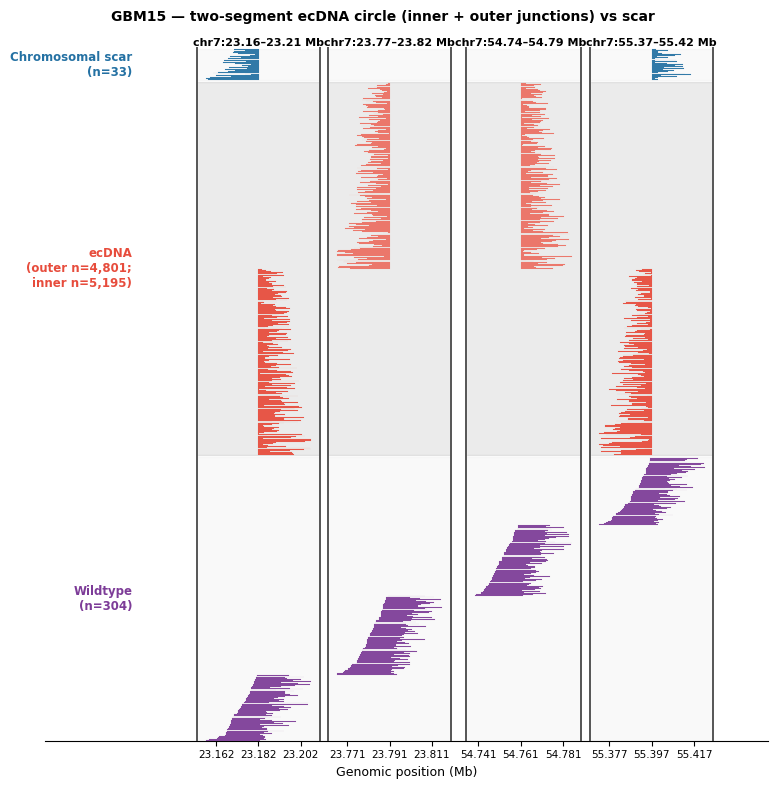

In [6]:
fig, reads15 = plot_gbm15_circle(
    paf15, sample="GBM15", chrom="chr7",
    segA_left=23_182_221, segA_right=23_791_139,
    segB_left=54_761_210, segB_right=55_396_729,
    scar_left=23_182_716, scar_right=55_396_759,
    window=25_000, region_gap=12_000,
    ecdna_subsample=200, gap_rows=1, border_pad_frac=0.08,
    merge_wildtype=True, show_both=False, figsize=(8, 8),
    outpath=OUT / "GBM15_scar_vs_ecdna.png",
)
display(fig); plt.close(fig)

## 3. GBM20

GBM20 is more complex. The chr7 breakpoints that flank the EGFR amplicon are not joined to each other; each is joined to **chromosome 1**. The chr1 piece is only a few kb, so every chr1 anchor lies within ~200 bp of the others, and "any alignment near anchor A and any alignment near anchor B" would wrongly assign ecDNA reads to the scar junctions. Junctions are therefore assigned **by read adjacency**: a read supports a junction only if two alignments that are *consecutive in the read* have their facing ends at the two junction coordinates.

| Junction | Class | Coordinates |
|---|---|---|
| J1 | scar A | chr7:54,736,853 ↔ chr1:85,267,331 |
| J2 | ecDNA | chr7:54,736,894 ↔ chr1:85,264,566 |
| J3 | ecDNA | chr7:55,296,841 ↔ chr1:85,267,537 |
| J4 | scar B | chr7:55,298,111 ↔ chr1:83,553,776 |

An **ecDNA read** supports J2 *or* J3, touches the chr1:85 Mb ecDNA cluster and at least one chr7 ecDNA boundary, and has all alignments inside those windows. **Scar reads** support J1 or J4 and are not ecDNA reads.

### 3.1 Classification and viewer functions

In [7]:
COL_WT, COL_WT_CHR1 = "#7D3C98", "#F2B342"           # chr7 / chr1 reference reads
COL_CIRC_BOTH, COL_SCAR_A, COL_SCAR_B = "#922B21", "#2471A3", "#5DADE2"

# Junctions: (name, kind, chromA, posA, chromB, posB)
JUNCTIONS = [
    ("J1", "scarA", "chr7", 54_736_853, "chr1", 85_267_331),
    ("J2", "ecDNA", "chr7", 54_736_894, "chr1", 85_264_566),
    ("J3", "ecDNA", "chr7", 55_296_841, "chr1", 85_267_537),
    ("J4", "scarB", "chr7", 55_298_111, "chr1", 83_553_776),
]
# Plotting windows: (name, chrom, low_anchor, high_anchor, pad)
WINDOWS = [
    ("W1", "chr7", 54_736_853, 54_736_894, 20_000),
    ("W2", "chr7", 55_296_841, 55_298_111, 20_000),
    ("W3", "chr1", 85_264_566, 85_267_537, 14_000),
    ("W4", "chr1", 83_553_776, 83_553_776, 20_000),
]
ECDNA_ALLOWED_WINDOWS = {"W1", "W2", "W3"}

def _seg_ends(row):
    """Genomic coordinates of an alignment's two read-oriented ends: (at qstart, at qend)."""
    return (row["tstart"], row["tend"]) if row["strand"] == "+" else (row["tend"], row["tstart"])

def realized_junctions(g):
    """Order one read's alignments by query coordinate and return the genomic adjacencies
    between consecutive segments: (chromA, posA, chromB, posB)."""
    g = g.sort_values(["qstart", "qend"]).reset_index(drop=True)
    out = []
    for i in range(len(g) - 1):
        a, b = g.iloc[i], g.iloc[i + 1]
        _, a_end = _seg_ends(a)
        b_start, _ = _seg_ends(b)
        out.append((a["tname"], a_end, b["tname"], b_start))
    return out

def supports(realized, cA, pA, cB, pB, tol=200):
    for rcA, rpA, rcB, rpB in realized:
        if rcA == cA and rcB == cB and abs(rpA - pA) <= tol and abs(rpB - pB) <= tol:
            return True
        if rcA == cB and rcB == cA and abs(rpA - pB) <= tol and abs(rpB - pA) <= tol:
            return True
    return False

def make_region_defs_with_gaps(regions, gaps_after):
    defs, off = [], 0
    for i, (chrom, start, end) in enumerate(regions):
        defs.append(dict(chrom=chrom, start=start, end=end, offset=off, width=end - start))
        if i < len(regions) - 1:
            off += (end - start) + (gaps_after[i] if i < len(gaps_after) else gaps_after[-1])
    return defs

def _aligned_span_in_region(g, region):
    chrom, start, end = region
    sub = g[(g["tname"] == chrom) & (g["tend"] >= start) & (g["tstart"] <= end)]
    if sub.empty:
        return 0
    return (sub["tend"].clip(upper=end) - sub["tstart"].clip(lower=start)).clip(lower=0).sum()

def _min_start_in_region(g, region):
    chrom, start, end = region
    sub = g[(g["tname"] == chrom) & (g["tend"] >= start) & (g["tstart"] <= end)]
    return float("inf") if sub.empty else sub["tstart"].min()

def _total_span_in_regions(g, regions):
    return sum(_aligned_span_in_region(g, reg) for reg in regions)

def _subsample_evenly(lst, n):
    if n is None or len(lst) <= n:
        return lst, len(lst)
    idx = sorted(set(np.linspace(0, len(lst) - 1, n).round().astype(int).tolist()))
    return [lst[i] for i in idx], len(lst)

def reads_spanning_positions(paf, chrom, positions, margin=500, min_mapq=20, exclude_qnames=frozenset()):
    """Reference-spanning reads: one alignment covers [pos-margin, pos+margin] for at least one anchor."""
    sub = paf[(paf["tname"] == chrom) & (paf["mapq"] >= min_mapq)]
    out = set()
    for pos in positions:
        out |= set(sub[(sub["tstart"] <= pos - margin) & (sub["tend"] >= pos + margin)]["qname"])
    return out - set(exclude_qnames)

def _sort_wt_for_region(names, paf, region):
    chrom, start, end = region
    rows = []
    for q in names:
        g = paf[(paf["qname"] == q) & (paf["tname"] == chrom) & (paf["tend"] >= start) & (paf["tstart"] <= end)]
        if not g.empty:
            rows.append((q, g["tstart"].min()))
    rows.sort(key=lambda x: x[1])
    return [q for q, _ in rows]

def _window_of_pos(chrom, pos, pad_extra=3000):
    for name, wchrom, lo, hi, pad in WINDOWS:
        if chrom == wchrom and min(lo, hi) - pad - pad_extra <= pos <= max(lo, hi) + pad + pad_extra:
            return name
    return None

def read_touched_windows(g, pad_extra=3000):
    touched = set()
    for _, row in g.iterrows():
        for p in (row["tstart"], row["tend"]):
            w = _window_of_pos(row["tname"], p, pad_extra)
            if w is not None:
                touched.add(w)
    return touched

def is_clean_for_ecdna(g, allowed_windows=ECDNA_ALLOWED_WINDOWS, pad_extra=3000):
    """Every alignment must land in an allowed ecDNA window (excludes e.g. reads reaching the chr1:83 Mb scar window)."""
    for _, row in g.iterrows():
        w1 = _window_of_pos(row["tname"], row["tstart"], pad_extra)
        w2 = _window_of_pos(row["tname"], row["tend"], pad_extra)
        if w1 not in allowed_windows and w2 not in allowed_windows:
            return False
    return True

def classify_gbm20(paf, tol=200, min_mapq=20, pad_extra=3000):
    """ecDNA = supports J2 OR J3, touches W3 (chr1 ecDNA cluster) and W1 or W2, and is clean in W1/W2/W3.
    Scar A = supports J1 and is not ecDNA; scar B = supports J4 and is not ecDNA."""
    sub = paf[paf["mapq"] >= min_mapq].copy()
    multi = sub[sub.groupby("qname")["qname"].transform("count") >= 2]
    groups = {q: g.copy() for q, g in multi.groupby("qname")}
    realized = {q: realized_junctions(g) for q, g in groups.items()}
    read_junctions = {q: {name for name, kind, cA, pA, cB, pB in JUNCTIONS if supports(rj, cA, pA, cB, pB, tol=tol)}
                      for q, rj in realized.items()}
    J = {n: {q for q, s in read_junctions.items() if n in s} for n in ["J1", "J2", "J3", "J4"]}
    ecDNA = set()
    for q, g in groups.items():
        js = read_junctions[q]
        if "J2" not in js and "J3" not in js:
            continue
        touched = read_touched_windows(g, pad_extra)
        if "W3" not in touched or not ({"W1", "W2"} & touched):
            continue
        if not is_clean_for_ecdna(g, pad_extra=pad_extra):
            continue
        ecDNA.add(q)
    scarA, scarB = J["J1"] - ecDNA, J["J4"] - ecDNA
    counts = {"J1_raw": len(J["J1"]), "J2_raw": len(J["J2"]), "J3_raw": len(J["J3"]), "J4_raw": len(J["J4"]),
              "J2_or_J3_raw": len(J["J2"] | J["J3"]), "J2_and_J3_raw": len(J["J2"] & J["J3"]),
              "ecDNA": len(ecDNA), "scarA": len(scarA), "scarB": len(scarB)}
    return dict(groups=groups, read_junctions=read_junctions, **J, ecDNA=ecDNA, scarA=scarA, scarB=scarB, counts=counts)

def sort_and_subsample_ecdna(read_names, paf, regions, read_junctions, max_total=200, min_per_group=40):
    """Order ecDNA reads as J2-only, J3-only, J2+J3, keeping each class represented when subsampling."""
    W1, W2, W3 = regions[0], regions[1], regions[3]
    groups = {"J2_only": [], "J3_only": [], "J2_J3": [], "other": []}
    for q in read_names:
        js = read_junctions.get(q, set())
        g = paf[paf["qname"] == q]
        tot, c1 = _total_span_in_regions(g, regions), _aligned_span_in_region(g, W3)
        if "J2" in js and "J3" in js:
            groups["J2_J3"].append((q, (-tot, _min_start_in_region(g, W1), _min_start_in_region(g, W2), -c1)))
        elif "J2" in js:
            groups["J2_only"].append((q, (_min_start_in_region(g, W1), -tot, -c1)))
        elif "J3" in js:
            groups["J3_only"].append((q, (_min_start_in_region(g, W2), -tot, -c1)))
        else:
            groups["other"].append((q, (-tot,)))
    srt = {k: [q for q, _ in sorted(v, key=lambda x: x[1])] for k, v in groups.items()}
    order = ["J2_only", "J3_only", "J2_J3", "other"]
    if max_total is None:
        final = [q for k in order for q in srt[k]]
    else:
        selected = []
        for k in order:
            slots = max_total - len(selected)
            if srt[k] and slots > 0:
                selected.extend(_subsample_evenly(srt[k], min(min_per_group, len(srt[k]), slots))[0])
        slots = max_total - len(selected)
        if slots > 0:
            have = set(selected)
            pool = [q for k in order for q in srt[k] if q not in have]
            selected.extend(_subsample_evenly(pool, slots)[0])
        keep = set(selected)
        final = [q for k in ["J2_J3", "J3_only", "J2_only", "other"] for q in srt[k] if q in keep]
    info = {"total_by_group": {k: len(v) for k, v in srt.items()},
            "shown_by_group": {k: sum(1 for q in final if q in set(v)) for k, v in srt.items()}}
    return final, info

In [8]:
def plot_gbm20_circle_vs_scars(paf, sample="GBM20", tol=200, min_mapq=20, region_gap=12_000, chr1_inner_gap=12_000,
                               ecdna_subsample=200, ecdna_min_per_group=40, wt_subsample_per_window=80,
                               span_margin=500, show_wildtype=True, rasterize_reads=True, dpi=400,
                               border_pad_frac=0.08, bar_h=0.9, gap_rows=1, figsize=(8, 8),
                               x_buffer_frac=0.04, outpath=None):
    """Scars on top, ecDNA in the middle, reference-spanning reads at the bottom.
    Columns: chr7:54 Mb | chr7:55 Mb | chr1:83 Mb | chr1:85 Mb."""
    cls = classify_gbm20(paf, tol=tol, min_mapq=min_mapq)
    c = cls["counts"]
    print(f"{sample}:")
    print(f"  J2 support, chr7:54,736,894 <-> chr1:85,264,566: {c['J2_raw']:,}")
    print(f"  J3 support, chr7:55,296,841 <-> chr1:85,267,537: {c['J3_raw']:,}")
    print(f"  J2 OR J3: {c['J2_or_J3_raw']:,}   J2 AND J3: {c['J2_and_J3_raw']:,}")
    print(f"  Clean ecDNA reads: {c['ecDNA']:,}   scar A (J1): {c['scarA']:,}   scar B (J4): {c['scarB']:,}")

    REGIONS = [("chr7", 54_736_853 - 20_000, 54_736_894 + 20_000),   # W1
               ("chr7", 55_296_841 - 20_000, 55_298_111 + 20_000),   # W2
               ("chr1", 83_553_776 - 20_000, 83_553_776 + 20_000),   # W4
               ("chr1", 85_264_566 - 14_000, 85_267_537 + 14_000)]   # W3
    rdefs = make_region_defs_with_gaps(REGIONS, [region_gap, region_gap, chr1_inner_gap])

    ecDNA_sel, info = sort_and_subsample_ecdna(cls["ecDNA"], paf, REGIONS, cls["read_junctions"],
                                               max_total=ecdna_subsample, min_per_group=ecdna_min_per_group)
    print("  ecDNA read classes (total / shown):")
    for k in ["J2_only", "J3_only", "J2_J3", "other"]:
        print(f"    {k}: {info['total_by_group'][k]:,} / {info['shown_by_group'][k]:,}")

    scarA_sel = _sort_by_total(cls["scarA"], paf, REGIONS)
    scarB_sel = _sort_by_total(cls["scarB"], paf, REGIONS)

    used_sv = set(cls["ecDNA"]) | set(cls["scarA"]) | set(cls["scarB"])
    wt1 = wt2 = wt3 = wt4 = []
    wt_tot = dict(w1=0, w2=0, w3=0, w4=0)
    if show_wildtype:
        s1 = reads_spanning_positions(paf, "chr7", [54_736_853, 54_736_894], span_margin, min_mapq, used_sv)
        s2 = reads_spanning_positions(paf, "chr7", [55_296_841, 55_298_111], span_margin, min_mapq, used_sv | s1)
        s4 = reads_spanning_positions(paf, "chr1", [83_553_776], span_margin, min_mapq, used_sv | s1 | s2)
        s3 = reads_spanning_positions(paf, "chr1", [85_264_566, 85_267_331, 85_267_537], span_margin, min_mapq,
                                      used_sv | s1 | s2 | s4)
        wt1 = _sort_wt_for_region(s1, paf, REGIONS[0]); wt2 = _sort_wt_for_region(s2, paf, REGIONS[1])
        wt4 = _sort_wt_for_region(s4, paf, REGIONS[2]); wt3 = _sort_wt_for_region(s3, paf, REGIONS[3])
        wt_tot = dict(w1=len(wt1), w2=len(wt2), w4=len(wt4), w3=len(wt3))
        wt1, wt2, wt4, wt3 = [_subsample_evenly(w, wt_subsample_per_window)[0] for w in (wt1, wt2, wt4, wt3)]
        print("  Reference-spanning reads (total / shown):")
        for lab, t, s in [("chr7:54 Mb", wt_tot["w1"], wt1), ("chr7:55 Mb", wt_tot["w2"], wt2),
                          ("chr1:83 Mb", wt_tot["w4"], wt4), ("chr1:85 Mb", wt_tot["w3"], wt3)]:
            print(f"    {lab}: {t:,} / {len(s):,}")

    sel_names = set(ecDNA_sel + scarA_sel + scarB_sel + wt1 + wt2 + wt4 + wt3)
    clipped = clip_paf(paf[paf["qname"].isin(sel_names)], rdefs)
    xmin_t, xmax_t = compute_tight_xrange(clipped, rdefs, buffer_frac=x_buffer_frac)
    label_pad = (xmax_t - xmin_t) * 0.18

    G = lambda n=gap_rows: [("__gap__", None, None)] * n
    stack = []
    if show_wildtype:
        stack += ([(r, COL_WT, "ref_w1") for r in wt1] + G() + [(r, COL_WT, "ref_w2") for r in wt2] + G() +
                  [(r, COL_WT_CHR1, "ref_w4") for r in wt4] + G() + [(r, COL_WT_CHR1, "ref_w3") for r in wt3] + G(gap_rows * 3))
    stack += [(r, COL_CIRC_BOTH, "ecDNA") for r in ecDNA_sel] + G(gap_rows * 3)
    stack += [(r, COL_SCAR_B, "scarB") for r in scarB_sel] + G() + [(r, COL_SCAR_A, "scarA") for r in scarA_sel]

    fig, ax = plt.subplots(figsize=figsize)
    group_ys, y = {}, 0
    for q, color, grp in stack:
        if q == "__gap__":
            y += 1
            continue
        group_ys.setdefault(grp, []).append(y)
        for _, row in clipped[clipped["qname"] == q].iterrows():
            x0, x1 = row["tstart_plot"], row["tend_plot"]
            if x1 > x0:
                ax.add_patch(Rectangle((x0, y - bar_h / 2), x1 - x0, bar_h, facecolor=color, edgecolor=color,
                                       linewidth=0.05, alpha=0.92, zorder=3, rasterized=rasterize_reads))
        y += 1

    ordered, seen = [], set()
    for q, _, grp in stack:
        if grp is not None and grp not in seen:
            seen.add(grp); ordered.append(grp)
    for gi, grp in enumerate(ordered):
        ys = group_ys.get(grp, [])
        if ys:
            pad = max(gap_rows * 0.4, 0.5)
            ax.axhspan(min(ys) - 0.5 - pad, max(ys) + 0.5 + pad, color="#00000006" if gi % 2 == 0 else "#00000014", zorder=0)

    label_map = {
        "scarA": (f"Scar A\nJ1 n={len(scarA_sel):,}", COL_SCAR_A),
        "scarB": (f"Scar B\nJ4 n={len(scarB_sel):,}", COL_SCAR_B),
        "ecDNA": (f"ecDNA\nshown {len(ecDNA_sel):,} of {c['ecDNA']:,}\nJ2 n={c['J2_raw']:,}; J3 n={c['J3_raw']:,}", COL_CIRC_BOTH),
        "ref_w1": (f"Reference\nchr7:54\nshown {len(wt1):,} of {wt_tot['w1']:,}", COL_WT),
        "ref_w2": (f"Reference\nchr7:55\nshown {len(wt2):,} of {wt_tot['w2']:,}", COL_WT),
        "ref_w4": (f"Reference\nchr1:83\nshown {len(wt4):,} of {wt_tot['w4']:,}", COL_WT_CHR1),
        "ref_w3": (f"Reference\nchr1:85\nshown {len(wt3):,} of {wt_tot['w3']:,}", COL_WT_CHR1),
    }
    for grp, ys in group_ys.items():
        lbl, col = label_map[grp]
        ax.text(xmin_t - label_pad * 0.55, (min(ys) + max(ys)) / 2, lbl, ha="right", va="center",
                fontsize=8.3, fontweight="bold", color=col)

    for reg in rdefs:
        ax.text(reg["offset"] + reg["width"] / 2, y + 0.8, f'{reg["chrom"]}:{reg["start"]/1e6:.3f}–{reg["end"]/1e6:.3f}',
                ha="center", va="bottom", fontsize=8, fontweight="bold")
    tp, tl = [], []
    for reg in rdefs:
        for f in [0.1, 0.5, 0.9]:
            tp.append(reg["offset"] + reg["width"] * f)
            tl.append(f"{(reg['start'] + reg['width'] * f) / 1e6:.3f}")
    ax.set_xticks(tp); ax.set_xticklabels(tl, fontsize=7.5)
    ax.set_xlabel("Genomic position (Mb)", fontsize=9)
    x_extra = (xmax_t - xmin_t) * border_pad_frac
    ax.set_xlim(xmin_t - label_pad - x_extra, xmax_t + x_extra)
    ax.set_ylim(-0.5, y + 1.5)

    # column borders; everything outside the columns is whited out
    full = [(r["offset"], r["offset"] + r["width"]) for r in rdefs]
    pad_amt = max((hi - lo for lo, hi in full), default=0) * border_pad_frac
    edges = [(lo - pad_amt, hi + pad_amt) for lo, hi in full]
    x_lo, x_hi = xmin_t - label_pad - x_extra, xmax_t + x_extra
    full_w = x_hi - x_lo
    ax.axvspan(x_lo - full_w * 0.1, edges[0][0], color="white", zorder=2)
    for i in range(len(rdefs) - 1):
        ax.axvspan(edges[i][1], edges[i + 1][0], color="white", zorder=2)
    ax.axvspan(edges[-1][1], x_hi + full_w * 0.1, color="white", zorder=2)
    bxs = [edges[0][0]]
    for i in range(len(rdefs) - 1):
        bxs += [edges[i][1], edges[i + 1][0]]
    bxs.append(edges[-1][1])
    for bx in bxs:
        ax.axvline(bx, color="#555555", lw=1.4, zorder=4)

    ax.set_yticks([])
    ax.spines[["top", "right", "left"]].set_visible(False)
    fig.suptitle(f"{sample} — interchromosomal ecDNA junctions, scars, and reference reads", fontsize=10, fontweight="bold")
    plt.tight_layout()
    if outpath:
        fig.savefig(outpath, dpi=dpi, bbox_inches="tight")
    return fig, dict(ecDNA=ecDNA_sel, scarA=scarA_sel, scarB=scarB_sel, counts=c, ecDNA_group_info=info)

### 3.2 GBM20: ecDNA junctions vs scars

Top to bottom: scar B, scar A, ecDNA (ordered J2-only, J3-only, then reads crossing both junctions), and reference-spanning reads. Columns are chr7:54 Mb, chr7:55 Mb, chr1:83 Mb and chr1:85 Mb. Reads crossing **both** J2 and J3 are single molecules that traverse chr7 → chr1 → chr7, i.e. direct evidence for the circle.

Loaded 24,797 alignments, 20,766 reads
GBM20:
  J2 support, chr7:54,736,894 <-> chr1:85,264,566: 736
  J3 support, chr7:55,296,841 <-> chr1:85,267,537: 722
  J2 OR J3: 863   J2 AND J3: 595
  Clean ecDNA reads: 406   scar A (J1): 28   scar B (J4): 24
  ecDNA read classes (total / shown):
    J2_only: 135 / 67
    J3_only: 44 / 41
    J2_J3: 227 / 92
    other: 0 / 0
  Reference-spanning reads (total / shown):
    chr7:54 Mb: 95 / 80
    chr7:55 Mb: 108 / 80
    chr1:83 Mb: 73 / 73
    chr1:85 Mb: 50 / 50


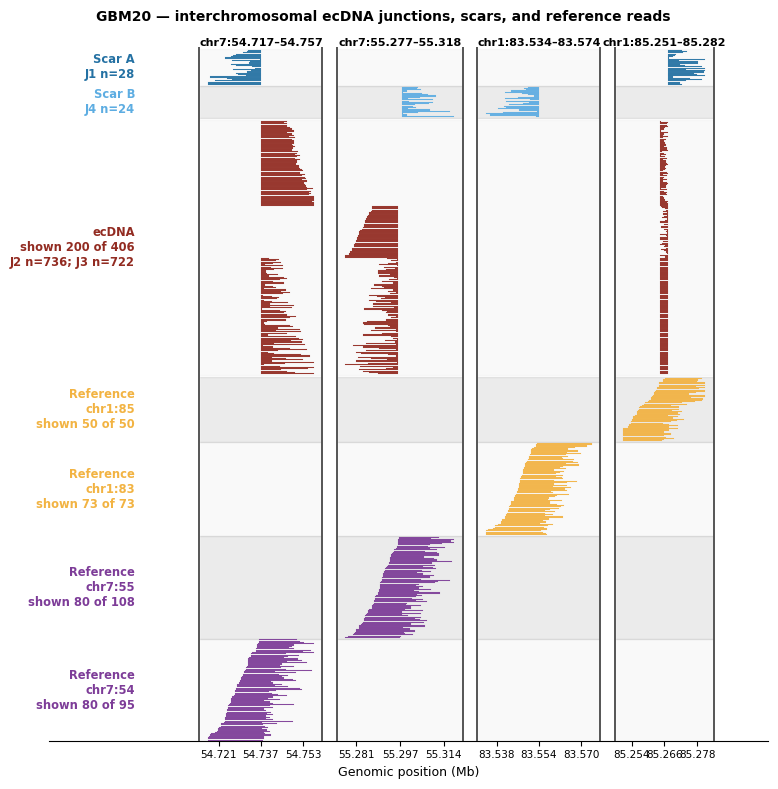

In [9]:
paf20 = read_paf(PAF_GBM20)
print(f"Loaded {len(paf20):,} alignments, {paf20['qname'].nunique():,} reads")

fig, reads20 = plot_gbm20_circle_vs_scars(
    paf20, sample="GBM20", tol=200, min_mapq=20,
    ecdna_subsample=200, ecdna_min_per_group=40, wt_subsample_per_window=80,
    span_margin=500, show_wildtype=True, gap_rows=1,
    border_pad_frac=0.08, figsize=(8, 8),
    outpath=OUT / "GBM20_splitreads.png",
)
display(fig); plt.close(fig)

## 4. GBM19

GBM19 is the simplest case: a single ecDNA junction closing the ~0.5-Mb amplicon, and a much lower-count **chromosomal deletion junction** at nearby but different positions (the scar). Because the deleted interval lies inside the amplified one, the scar is not visible in copy-number data and is evidenced only by junction-spanning reads.

### 4.1 All split-read alignments in the locus

`plot_paf` draws every alignment of every split read (mapping quality > 50) in chr7:54.0-56.0 Mb, coloured by strand, one row per read. The shaded band is the EGFR gene.

In [10]:
from matplotlib.patches import FancyArrowPatch, Patch

def _pack_reads(df, start_col="tstart_plot", end_col="tend_plot"):
    spans = df.groupby("qname").agg({start_col: "min", end_col: "max"}).reset_index().sort_values(start_col)
    lanes_end, lane_of = [], {}
    for _, row in spans.iterrows():
        q, s, e = row["qname"], row[start_col], row[end_col]
        for i, le in enumerate(lanes_end):
            if s >= le:
                lane_of[q] = i; lanes_end[i] = e
                break
        else:
            lane_of[q] = len(lanes_end); lanes_end.append(e)
    return lane_of, len(lanes_end)

def genomic_pos_to_plot_x(chrom, pos, region_defs):
    for reg in region_defs:
        if reg["chrom"] == chrom and reg["start"] <= pos <= reg["end"]:
            return reg["offset"] + (pos - reg["start"])
    return None

def plot_paf(df, chrom="chr7", start=54_000_000, end=57_000_000, regions=None, region_gap=10_000,
             max_reads=5000, pack=True, color_by="strand", egfr_region=(55_019_017, 55_211_628),
             markers=None, junctions=None, min_junction_support=3, figsize=(18, 6), alpha=0.75, title=None):
    """Plot every alignment of the given reads (one row per read, or packed), coloured by strand.
    markers: optional list of (chrom, pos, colour) vertical lines."""
    if regions is None:
        regions = [(chrom, start, end)]
    region_defs, offset = [], 0
    for rchrom, rstart, rend in regions:
        region_defs.append({"chrom": rchrom, "start": rstart, "end": rend, "offset": offset, "width": rend - rstart})
        offset += (rend - rstart) + region_gap

    pieces = []
    for reg in region_defs:
        sub = df[df["tname"] == reg["chrom"]].copy()
        sub = sub[(sub["tend"] >= reg["start"]) & (sub["tstart"] <= reg["end"])]
        if sub.empty:
            continue
        sub["tstart_clip"] = sub["tstart"].clip(lower=reg["start"], upper=reg["end"])
        sub["tend_clip"] = sub["tend"].clip(lower=reg["start"], upper=reg["end"])
        sub = sub[sub["tend_clip"] > sub["tstart_clip"]].copy()
        sub["tstart_plot"] = reg["offset"] + (sub["tstart_clip"] - reg["start"])
        sub["tend_plot"] = reg["offset"] + (sub["tend_clip"] - reg["start"])
        pieces.append(sub)
    if not pieces:
        print("No alignments in requested regions")
        return None, None
    d = pd.concat(pieces, ignore_index=True)
    d = d[d["qname"].isin(d["qname"].drop_duplicates().tolist()[:max_reads])].copy()

    if pack:
        y_map, n_lanes = _pack_reads(d)
    else:
        y_map = {r: i for i, r in enumerate(d["qname"].drop_duplicates().tolist())}
        n_lanes = len(y_map)

    fig, ax = plt.subplots(figsize=figsize)
    bar_h = 0.85
    for i, reg in enumerate(region_defs):
        ax.axvspan(reg["offset"], reg["offset"] + reg["width"], color="grey", alpha=0.04 if i % 2 == 0 else 0.02, zorder=0)
        ax.axvline(reg["offset"], color="black", lw=0.8, alpha=0.35, zorder=1)
        ax.axvline(reg["offset"] + reg["width"], color="black", lw=0.8, alpha=0.35, zorder=1)
    if egfr_region is not None:
        for reg in region_defs:
            if reg["chrom"] != "chr7" or egfr_region[1] < reg["start"] or egfr_region[0] > reg["end"]:
                continue
            s, e = max(egfr_region[0], reg["start"]), min(egfr_region[1], reg["end"])
            ax.axvspan(reg["offset"] + (s - reg["start"]), reg["offset"] + (e - reg["start"]), color="royalblue", alpha=0.07, zorder=0)

    strand_colors = {"+": "#E8693A", "-": "#3A7EC8"}
    tp_colors = {"P": "#2CA02C", "S": "#9467BD"}
    for _, row in d.iterrows():
        x0, x1 = row["tstart_plot"], row["tend_plot"]
        if x1 <= x0:
            continue
        if color_by == "strand":
            color = strand_colors.get(row.get("strand", "+"), "#888")
        elif color_by == "tp":
            color = tp_colors.get(row.get("tp", ""), "#888")
        else:
            color = "#888"
        y = y_map[row["qname"]]
        ax.add_patch(Rectangle((x0, y - bar_h / 2), x1 - x0, bar_h, linewidth=0, alpha=alpha, color=color))

    ylim_top = n_lanes
    if junctions is not None and not junctions.empty:
        jd = junctions.rename(columns={"chrA": "chr1", "posA": "pos1", "chrB": "chr2", "posB": "pos2"})
        arcs = []
        for _, r in jd.iterrows():
            if r["support"] < min_junction_support:
                continue
            x1 = genomic_pos_to_plot_x(r["chr1"], r["pos1"], region_defs)
            x2 = genomic_pos_to_plot_x(r["chr2"], r["pos2"], region_defs)
            if x1 is not None and x2 is not None and x1 != x2:
                arcs.append((x1, x2, r["support"]))
        if arcs:
            sup = np.array([a[2] for a in arcs], dtype=float)
            sn = (sup - sup.min()) / (sup.max() - sup.min() + 1e-9)
            for (x1, x2, _), s in zip(arcs, sn):
                ax.add_patch(FancyArrowPatch((x1, n_lanes + 0.3), (x2, n_lanes + 0.3), arrowstyle="-",
                                             linewidth=1 + s * 3, alpha=0.7, color="#333",
                                             connectionstyle=f"arc3,rad={-(0.25 + 0.35 * s)}", zorder=3))
            ylim_top = n_lanes + 2.0
    ax.set_ylim(-1, ylim_top)

    tick_positions, tick_labels = [], []
    for reg in region_defs:
        span = reg["end"] - reg["start"]
        step, fmt = (1_000_000, "{:.0f}") if span >= 5_000_000 else (500_000, "{:.1f}") if span >= 1_000_000 else (100_000, "{:.2f}")
        tb = np.arange((reg["start"] // step) * step, reg["end"] + step, step)
        for t in tb[(tb >= reg["start"]) & (tb <= reg["end"])]:
            tick_positions.append(reg["offset"] + (t - reg["start"])); tick_labels.append(fmt.format(t / 1e6))
    ax.set_xticks(tick_positions); ax.set_xticklabels(tick_labels, fontsize=9)
    for reg in region_defs:
        ax.text(reg["offset"] + reg["width"] / 2, ax.get_ylim()[1] - 0.1,
                f'{reg["chrom"]}:{reg["start"]/1e6:.1f}-{reg["end"]/1e6:.1f} Mb',
                ha="center", va="bottom", fontsize=10, fontweight="bold")
    ax.set_xlim(0, region_defs[-1]["offset"] + region_defs[-1]["width"])
    ax.set_yticks([])
    ax.set_xlabel("Genomic position (Mb)", fontsize=11)
    ax.spines[["top", "right", "left"]].set_visible(False)
    if title:
        ax.set_title(title, fontsize=12, fontweight="bold")
    if color_by == "strand":
        ax.legend(handles=[Patch(color=strand_colors["+"], label="+ strand"), Patch(color=strand_colors["-"], label="− strand")],
                  fontsize=9, frameon=False, loc="upper left")
    for c_, p_, col_ in (markers or []):
        x = genomic_pos_to_plot_x(c_, p_, region_defs)
        if x is not None:
            ax.axvline(x=x, color=col_, linewidth=2, alpha=0.9, zorder=10)
    plt.tight_layout()
    return fig, ax

Loaded 161,923 alignments, 92,423 reads
124,505 high-quality alignments
Split reads: 12,440


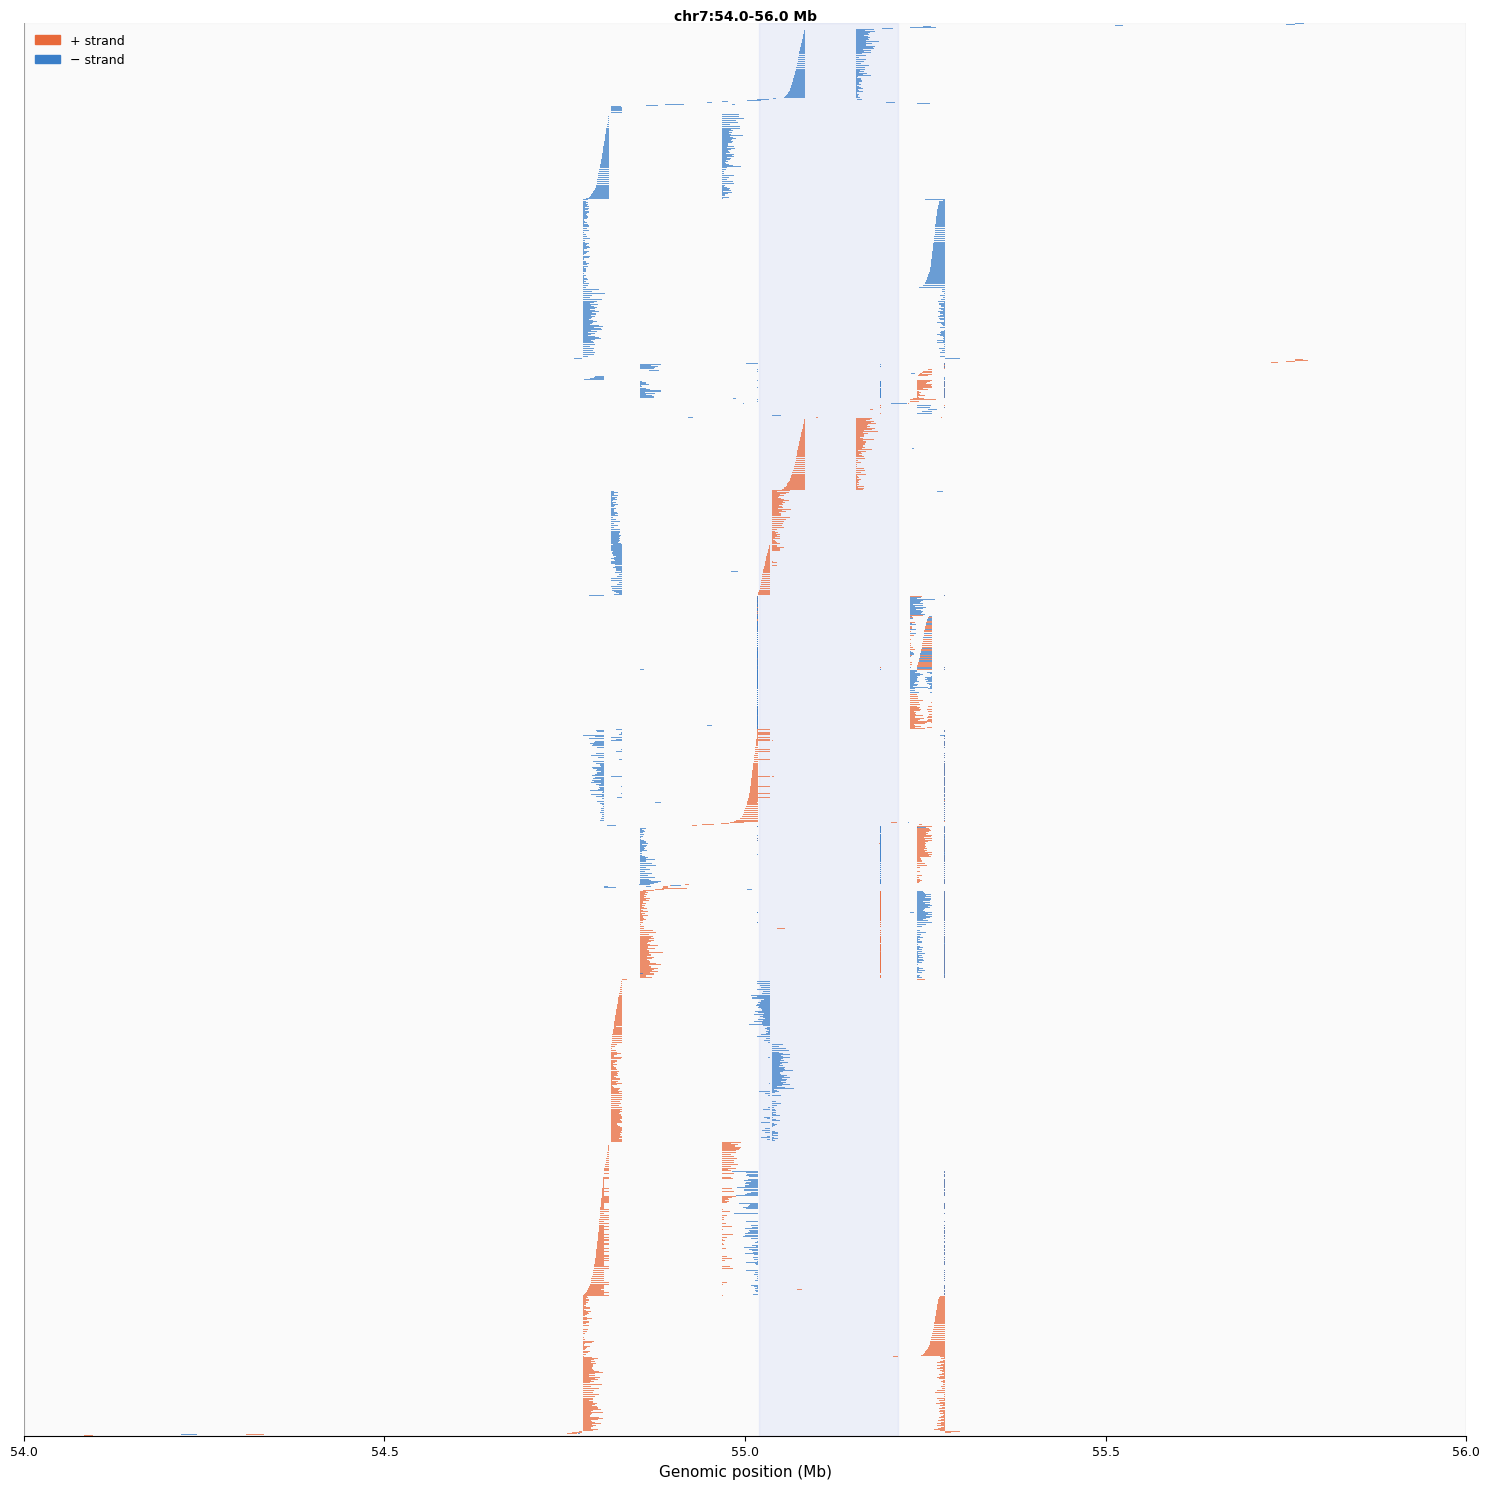

In [11]:
paf19 = read_paf(PAF_GBM19)
print(f"Loaded {len(paf19):,} alignments, {paf19['qname'].nunique():,} reads")
paf19 = paf19[paf19["mapq"] > 50].reset_index(drop=True)
print(f"{len(paf19):,} high-quality alignments")
split19 = paf19[paf19.groupby("qname")["qname"].transform("count") > 1]
print(f"Split reads: {split19['qname'].nunique():,}")

fig, ax = plot_paf(
    split19.sort_values(["strand", "tstart"]),
    regions=[("chr7", 54_000_000, 56_000_132)],
    pack=False, max_reads=60000, color_by="strand",
    egfr_region=(55_019_017, 55_211_628), figsize=(15, 15),
)
fig.savefig(OUT / "GBM19_split_reads.png", dpi=200, bbox_inches="tight")
display(fig); plt.close(fig)

### 4.2 Junctions

Junctions are discovered from the same split reads. The ecDNA junction is the high-count junction between the left and right ends of the amplicon; the scar is a lower-count junction between nearby, but different, left and right positions. `snap_junction` takes an approximate position for each end and returns the best-supported junction within 100 bp, so the exact breakpoint coordinates come from the data rather than being typed in.

In [12]:
COL_CIRC, COL_SCAR = "#C0392B", "#2471A3"      # ecDNA (red), scar (blue); reference reads reuse COL_WT

def reads_supporting_junction_g19(paf, chrom, posA, posB, tol=200, min_mapq=20, require_two_alignments=True):
    """Unique qnames supporting junction posA <-> posB. With require_two_alignments, only reads with
    EXACTLY two alignments on `chrom` are kept (clean junction reads)."""
    sub = paf[(paf["tname"] == chrom) & (paf["mapq"] >= min_mapq)].copy()
    n = sub.groupby("qname")["qname"].transform("count")
    cand = sub[n == 2] if require_two_alignments else sub[n > 1]
    out = set()
    for q, g in cand.groupby("qname"):
        ends, starts = g["tend"].values, g["tstart"].values
        if ((np.any(np.abs(ends - posA) <= tol) and np.any(np.abs(starts - posB) <= tol)) or
                (np.any(np.abs(ends - posB) <= tol) and np.any(np.abs(starts - posA) <= tol))):
            out.add(q)
    return out

def reads_spanning_wildtype_g19(paf, chrom, bp_positions, margin=500, min_mapq=20, exclude_qnames=frozenset()):
    """Reads with ONE continuous alignment covering [min(bp)-margin, max(bp)+margin] on a side, i.e. a
    molecule on which that boundary is not rearranged."""
    lo, hi = min(bp_positions) - margin, max(bp_positions) + margin
    sub = paf[(paf["tname"] == chrom) & (paf["mapq"] >= min_mapq)]
    return set(sub[(sub["tstart"] <= lo) & (sub["tend"] >= hi)]["qname"]) - set(exclude_qnames)

def sort_junction_reads(read_names, paf, left_region, right_region, mode="total_length"):
    """Order junction reads for a tidy fan (total aligned span by default)."""
    lc, ls, le = left_region
    rc, rs, re = right_region
    recs = []
    for q in read_names:
        g = paf[paf["qname"] == q]
        left = g[(g["tname"] == lc) & (g["tend"] >= ls) & (g["tstart"] <= le)]
        right = g[(g["tname"] == rc) & (g["tend"] >= rs) & (g["tstart"] <= re)]
        lx = (left["tend"].clip(upper=le) - left["tstart"].clip(lower=ls)).max() if not left.empty else 0
        rx = (right["tend"].clip(upper=re) - right["tstart"].clip(lower=rs)).max() if not right.empty else 0
        recs.append((q, lx, rx, lx + rx))
    df = pd.DataFrame(recs, columns=["qname", "left_ext", "right_ext", "total"])
    if mode == "total_length":
        df = df.sort_values(["total", "left_ext"], ascending=[False, False])
    elif mode == "left_extent":
        df = df.sort_values("left_ext", ascending=False)
    elif mode == "right_extent":
        df = df.sort_values("right_ext", ascending=False)
    elif mode == "balance":
        df["bal"] = df["left_ext"] - df["right_ext"]; df = df.sort_values("bal", ascending=False)
    else:
        raise ValueError("mode must be total_length, left_extent, right_extent, or balance")
    return df["qname"].tolist()

def snap_junction(summary, approx_A, approx_B, window=100):
    """Return the best-supported junction in a summarize_junctions() table whose two ends lie within
    `window` bp of the approximate coordinates (the exact coordinates then come from the data)."""
    s = summary[(summary["posA"].sub(approx_A).abs() <= window) & (summary["posB"].sub(approx_B).abs() <= window)]
    if s.empty:
        raise ValueError(f"No junction within {window} bp of {approx_A:,} / {approx_B:,}")
    r = s.sort_values("support", ascending=False).iloc[0]
    return int(r["posA"]), int(r["posB"]), int(r["support"])

def plot_scar_vs_ecdna(paf_all, sample, chrom, scar_posA, scar_posB, ecdna_posA, ecdna_posB,
                       window=50_000, region_gap=20_000, tol=200, min_mapq=20, span_margin=500,
                       show_wildtype=True, x_buffer_frac=0.04, ecdna_subsample=None, rasterize_reads=True,
                       dpi=400, border_pad_frac=0.06, bar_h=0.9, gap_rows=4, figsize=(8, 8), outpath=None):
    """Two-column viewer (left and right boundary). Rows top to bottom: reference-left, reference-right,
    ecDNA, scar."""
    scar_reads = reads_supporting_junction_g19(paf_all, chrom, scar_posA, scar_posB, tol=tol, min_mapq=min_mapq)
    ecdna_reads = reads_supporting_junction_g19(paf_all, chrom, ecdna_posA, ecdna_posB, tol=tol, min_mapq=min_mapq)
    scar_reads = scar_reads - ecdna_reads                 # a read cannot be both; ecDNA dominates
    used = scar_reads | ecdna_reads
    wt_left = reads_spanning_wildtype_g19(paf_all, chrom, [scar_posA, ecdna_posA], span_margin, min_mapq, used)
    wt_right = reads_spanning_wildtype_g19(paf_all, chrom, [scar_posB, ecdna_posB], span_margin, min_mapq, used | wt_left)
    print(f"{sample}: scar={len(scar_reads)}, ecDNA={len(ecdna_reads)}, WT-left={len(wt_left)}, WT-right={len(wt_right)}")

    left_anchor, right_anchor = min(scar_posA, ecdna_posA), max(scar_posB, ecdna_posB)
    REGIONS = [(chrom, left_anchor - window, left_anchor + window), (chrom, right_anchor - window, right_anchor + window)]
    rdefs = make_region_defs(REGIONS, region_gap)
    scar_sel = sort_junction_reads(scar_reads, paf_all, REGIONS[0], REGIONS[1])
    ecdna_sel = sort_junction_reads(ecdna_reads, paf_all, REGIONS[0], REGIONS[1])

    def _sort_wt(names, region):
        rc = region[0]
        rows = [(q, paf_all[(paf_all["qname"] == q) & (paf_all["tname"] == rc)]["tstart"].min()) for q in names
                if not paf_all[(paf_all["qname"] == q) & (paf_all["tname"] == rc)].empty]
        return [r[0] for r in sorted(rows, key=lambda x: x[1])]
    wt_left_sel = _sort_wt(wt_left, REGIONS[0]) if show_wildtype else []
    wt_right_sel = _sort_wt(wt_right, REGIONS[1]) if show_wildtype else []

    ecdna_full_n = len(ecdna_sel)
    if ecdna_subsample is not None and len(ecdna_sel) > ecdna_subsample:
        idx = sorted(set(np.linspace(0, len(ecdna_sel) - 1, ecdna_subsample).round().astype(int).tolist()))
        ecdna_sel = [ecdna_sel[i] for i in idx]

    sel = set(scar_sel) | set(ecdna_sel) | set(wt_left_sel) | set(wt_right_sel)
    clipped = clip_paf(paf_all[paf_all["qname"].isin(sel)], rdefs)
    xmin_t, xmax_t = compute_tight_xrange(clipped, rdefs, buffer_frac=x_buffer_frac)
    label_pad = (xmax_t - xmin_t) * 0.18

    G = [("__gap__", None, None)] * gap_rows
    stack = []
    if show_wildtype:
        stack += [(r, COL_WT, "wt_left") for r in wt_left_sel] + G + [(r, COL_WT, "wt_right") for r in wt_right_sel] + G
    stack += [(r, COL_CIRC, "ecDNA") for r in ecdna_sel] + G + [(r, COL_SCAR, "scar") for r in scar_sel]

    fig, ax = plt.subplots(figsize=figsize)
    group_ys, y = {}, 0
    for q, color, grp in stack:
        if q == "__gap__":
            y += 1; continue
        group_ys.setdefault(grp, []).append(y)
        for _, row in clipped[clipped["qname"] == q].iterrows():
            x0, x1 = row["tstart_plot"], row["tend_plot"]
            if x1 > x0:
                ax.add_patch(Rectangle((x0, y - bar_h / 2), x1 - x0, bar_h, facecolor=color, edgecolor=color,
                                       linewidth=0.05, alpha=0.92, zorder=3, rasterized=rasterize_reads))
        y += 1

    shades = {"wt_left": "#00000008", "wt_right": "#00000012", "ecDNA": "#00000008", "scar": "#00000012"}
    for grp, ys in group_ys.items():
        pad = max(gap_rows * 0.4, 0.5)
        ax.axhspan(min(ys) - 0.5 - pad, max(ys) + 0.5 + pad, color=shades.get(grp, "#00000008"), zorder=0)

    label_map = {"scar": (f"Chromosomal Scar\n(n={len(scar_sel):,})", COL_SCAR),
                 "ecDNA": (f"ecDNA\n(n={ecdna_full_n:,})" if ecdna_full_n == len(ecdna_sel)
                           else f"ecDNA\n(showing {len(ecdna_sel):,}\nof {ecdna_full_n:,})", COL_CIRC),
                 "wt_left": (f"Wildtype left\n(n={len(wt_left_sel):,})", COL_WT),
                 "wt_right": (f"Wildtype right\n(n={len(wt_right_sel):,})", COL_WT)}
    for grp, ys in group_ys.items():
        lbl, col = label_map[grp]
        ax.text(xmin_t - label_pad * 0.55, (min(ys) + max(ys)) / 2, lbl, ha="right", va="center",
                fontsize=9, fontweight="bold", color=col)
    for reg in rdefs:
        ax.text(reg["offset"] + reg["width"] / 2, y + 0.8, f'{reg["chrom"]}:{reg["start"]/1e6:.2f}–{reg["end"]/1e6:.2f} Mb',
                ha="center", va="bottom", fontsize=8.5, fontweight="bold")
    tp, tl = [], []
    for reg in rdefs:
        for f in [0.1, 0.5, 0.9]:
            tp.append(reg["offset"] + reg["width"] * f); tl.append(f"{(reg['start'] + reg['width'] * f) / 1e6:.3f}")
    ax.set_xticks(tp); ax.set_xticklabels(tl, fontsize=8)
    ax.set_xlabel("Genomic position (Mb)", fontsize=9)
    x_extra = (xmax_t - xmin_t) * border_pad_frac
    ax.set_xlim(xmin_t - label_pad - x_extra, xmax_t + x_extra)
    ax.set_ylim(-0.5, y + 1.5)

    # borders at the plotted read extent of each region; everything outside is whited out
    edges = []
    for reg in rdefs:
        lo, hi = reg["offset"], reg["offset"] + reg["width"]
        r = clipped[(clipped["tstart_plot"] >= lo - 1) & (clipped["tend_plot"] <= hi + 1)]
        edges.append((lo, hi) if r.empty else (r["tstart_plot"].min(), r["tend_plot"].max()))
    pad_amt = max((e[1] - e[0] for e in edges), default=0) * border_pad_frac
    edges = [(lo - pad_amt, hi + pad_amt) for lo, hi in edges]
    x_lo, x_hi = xmin_t - label_pad - x_extra, xmax_t + x_extra
    fw = x_hi - x_lo
    ax.axvspan(x_lo - fw * 0.1, edges[0][0], color="white", zorder=2)
    for i in range(len(rdefs) - 1):
        ax.axvspan(edges[i][1], edges[i + 1][0], color="white", zorder=2)
    ax.axvspan(edges[-1][1], x_hi + fw * 0.1, color="white", zorder=2)
    bxs = [edges[0][0]]
    for i in range(len(rdefs) - 1):
        bxs += [edges[i][1], edges[i + 1][0]]
    bxs.append(edges[-1][1])
    for bx in bxs:
        ax.axvline(bx, color="#555555", lw=1.4, zorder=4)
    ax.set_yticks([])
    ax.spines[["top", "right", "left"]].set_visible(False)
    fig.suptitle(f"{sample} — ecDNA circularization vs chromosomal scar", fontsize=10, fontweight="bold")
    plt.tight_layout()
    if outpath:
        fig.savefig(outpath, dpi=dpi, bbox_inches="tight")
    return fig, dict(scar=scar_sel, ecdna=ecdna_sel)

In [13]:
junc19 = extract_junctions(split19, min_mapq=20, same_chrom_only=True)
junc_summary19 = summarize_junctions(junc19, min_support=3, bin_bp=1)
junc_summary19 = junc_summary19[(junc_summary19["chrA"] == "chr7") & (junc_summary19["chrB"] == "chr7")]
display(junc_summary19.head(10))

# approximate seeds for the two junctions (left end, right end); exact positions are taken from the table
g19_ecdna_A, g19_ecdna_B, n_ecdna_bin = snap_junction(junc_summary19, 54_774_650, 55_277_300)
g19_scar_A,  g19_scar_B,  n_scar_bin  = snap_junction(junc_summary19, 54_774_372, 55_277_185)
print(f"ecDNA junction: chr7:{g19_ecdna_A:,} <-> chr7:{g19_ecdna_B:,}  ({n_ecdna_bin:,} reads at this exact position)")
print(f"scar  junction: chr7:{g19_scar_A:,} <-> chr7:{g19_scar_B:,}  ({n_scar_bin:,} reads at this exact position)")

,chrA,posA,chrB,posB,support
380,chr7,55017566,chr7,55112606,3427
646,chr7,55276916,chr7,55276926,2592
59,chr7,54774651,chr7,55277340,2420
362,chr7,55017541,chr7,55112901,1809
178,chr7,54854776,chr7,55276584,1386
552,chr7,55187677,chr7,55187958,1380
579,chr7,55187952,chr7,55276607,1368
117,chr7,54811711,chr7,54967954,1352
137,chr7,54814512,chr7,55112883,1352
170,chr7,54829154,chr7,55034292,1265


ecDNA junction: chr7:54,774,651 <-> chr7:55,277,340  (2,420 reads at this exact position)
scar  junction: chr7:54,774,372 <-> chr7:55,277,185  (30 reads at this exact position)


### 4.3 GBM19: ecDNA junction vs scar

Top to bottom: reference-spanning reads on the left and right boundaries (purple), ecDNA reads (red) and scar reads (blue). The two columns are the 100-kb windows around the left and right boundary. Reads are assigned to a junction if their two alignments end and start within 200 bp of its coordinates; only reads with exactly two alignments on chr7 count, and scar reads exclude ecDNA reads.

GBM19: scar=31, ecDNA=2482, WT-left=72, WT-right=61


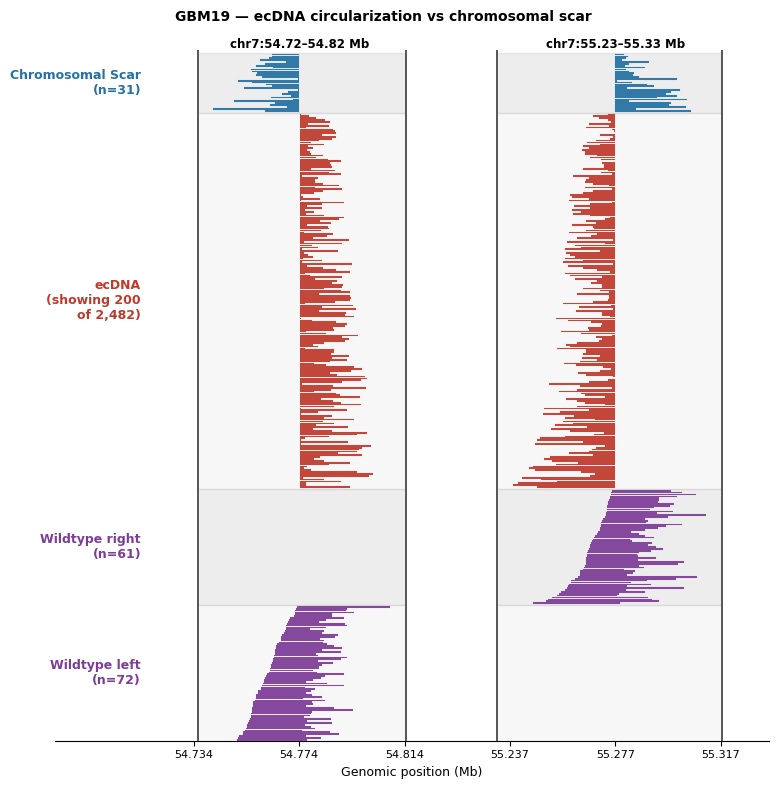

In [14]:
fig, reads19 = plot_scar_vs_ecdna(
    paf19, sample="GBM19", chrom="chr7",
    scar_posA=g19_scar_A, scar_posB=g19_scar_B,
    ecdna_posA=g19_ecdna_A, ecdna_posB=g19_ecdna_B,
    span_margin=500, show_wildtype=True,
    gap_rows=1, ecdna_subsample=200, border_pad_frac=0.08,
    rasterize_reads=True, dpi=400,
    outpath=OUT / "GBM19_scar_vs_ecdna.png",
)
display(fig); plt.close(fig)

## 5. Offsets between ecDNA and scar breakpoints

For each boundary, Δ is the distance in bp between the scar breakpoint and the ecDNA breakpoint on the same side. Non-zero values show that the two junctions are not reciprocal products of a single pair of breaks: the sequence between them is either lost from both the chromosome and the ecDNA (gap) or kept on both (overlap).

In [15]:
pairs = [
    ("GBM19", "left boundary (chr7:54.8 Mb)",  g19_scar_A, g19_ecdna_A),
    ("GBM19", "right boundary (chr7:55.3 Mb)", g19_scar_B, g19_ecdna_B),
    ("GBM15", "left boundary (chr7:23 Mb)",  23_182_716, 23_182_221),
    ("GBM15", "right boundary (chr7:55 Mb)", 55_396_759, 55_396_729),
    ("GBM20", "chr7 left (J1 vs J2)",        54_736_853, 54_736_894),
    ("GBM20", "chr7 right (J4 vs J3)",       55_298_111, 55_296_841),
    ("GBM20", "chr1 (J1 vs J3)",             85_267_331, 85_267_537),
]
offsets = pd.DataFrame(pairs, columns=["tumor", "boundary", "scar_pos", "ecDNA_pos"])
offsets["delta_bp"] = (offsets["scar_pos"] - offsets["ecDNA_pos"]).abs()
#offsets.to_csv(OUT / "fig2_breakpoint_offsets.csv", index=False)
offsets

,tumor,boundary,scar_pos,ecDNA_pos,delta_bp
0,GBM19,left boundary (chr7:54.8 Mb),54774372,54774651,279
1,GBM19,right boundary (chr7:55.3 Mb),55277185,55277340,155
2,GBM15,left boundary (chr7:23 Mb),23182716,23182221,495
3,GBM15,right boundary (chr7:55 Mb),55396759,55396729,30
4,GBM20,chr7 left (J1 vs J2),54736853,54736894,41
5,GBM20,chr7 right (J4 vs J3),55298111,55296841,1270
6,GBM20,chr1 (J1 vs J3),85267331,85267537,206


## Appendix: how the PAF files are made

Reads that touch the breakpoint regions are pulled from the whole-genome tumor BAM, converted to FASTQ (primary alignments only), and **re-aligned in full to the whole reference** so that every piece of a rearranged molecule, including pieces on other chromosomes, is represented.

**GBM15** (`UM215`):

In [ ]:
%%writefile make_paf_gbm15.sh
#!/bin/bash
set -euo pipefail

SAMPLE="UM215"
TUMOR_BAM="UM215_Tumor_merged.bam"
OUTDIR="scar_paf"
REF="GRCh38_full_analysis_set_plus_decoy_hla.fa"
THREADS=16
mkdir -p "${OUTDIR}"

# reads touching the four chr7 breakpoint regions
samtools view -@ ${THREADS} -b -M "${TUMOR_BAM}" \
    chr7:23000000-23350000 chr7:23650000-23950000 \
    chr7:54550000-54950000 chr7:55250000-55550000 \
  | samtools sort -@ ${THREADS} > "${OUTDIR}/${SAMPLE}_GBM15_chr7_ecDNA_breakpoints.bam"
samtools index "${OUTDIR}/${SAMPLE}_GBM15_chr7_ecDNA_breakpoints.bam"

# primary alignments -> FASTQ
samtools fastq -@ ${THREADS} -F 2304 "${OUTDIR}/${SAMPLE}_GBM15_chr7_ecDNA_breakpoints.bam" \
    > "${OUTDIR}/${SAMPLE}_GBM15_chr7_ecDNA_breakpoints.fastq"

# re-align whole molecules to the whole reference
minimap2 -x map-hifi -t ${THREADS} -c --cs "${REF}" \
    "${OUTDIR}/${SAMPLE}_GBM15_chr7_ecDNA_breakpoints.fastq" \
    > "${OUTDIR}/${SAMPLE}_GBM15_chr7_ecDNA_breakpoints.paf"
bgzip -@ ${THREADS} -f "${OUTDIR}/${SAMPLE}_GBM15_chr7_ecDNA_breakpoints.paf"

**GBM19** (`UM233`): the chr7:49-59 Mb tumor reads re-aligned to the whole reference the same way.

In [ ]:
%%writefile make_paf_gbm19.sh
#!/bin/bash
set -euo pipefail
SAMPLE="UM233"
REF="GRCh38_full_analysis_set_plus_decoy_hla.fa"
THREADS=16
samtools fastq -@ ${THREADS} -F 2304 "${SAMPLE}_Tumor_chr7_49_59mb.bam" > "${SAMPLE}_Tumor_chr7_49_59mb.fastq"
minimap2 -x map-hifi -t ${THREADS} -c --cs "${REF}" "${SAMPLE}_Tumor_chr7_49_59mb.fastq" \
    > "${SAMPLE}_Tumor_chr7_49_59mb.paf"
bgzip -@ ${THREADS} -f "${SAMPLE}_Tumor_chr7_49_59mb.paf"

**GBM20** (`UM-244`): same procedure with chr7 and chr1 breakpoint regions.

In [ ]:
%%writefile make_paf_gbm20.sh
#!/bin/bash
set -euo pipefail

SAMPLE="UM-244"
TUMOR_BAM="UM-244_Tumor.bam"
OUTDIR="scar_paf"
REF="GRCh38_full_analysis_set_plus_decoy_hla.fa"
THREADS=16
mkdir -p "${OUTDIR}"

samtools view -@ ${THREADS} -b -M "${TUMOR_BAM}" \
    chr7:54600000-54900000 chr7:55150000-55450000 \
    chr1:83400000-83700000 chr1:85100000-85400000 \
  | samtools sort -@ ${THREADS} > "${OUTDIR}/${SAMPLE}_breakpoint_regions.bam"
samtools index "${OUTDIR}/${SAMPLE}_breakpoint_regions.bam"

samtools fastq -@ ${THREADS} -F 2304 "${OUTDIR}/${SAMPLE}_breakpoint_regions.bam" \
    > "${OUTDIR}/${SAMPLE}_breakpoint_regions.fastq"

minimap2 -x map-hifi -t ${THREADS} -c --cs "${REF}" \
    "${OUTDIR}/${SAMPLE}_breakpoint_regions.fastq" \
    > "${OUTDIR}/${SAMPLE}_breakpoint_regions.paf"
bgzip -@ ${THREADS} -f "${OUTDIR}/${SAMPLE}_breakpoint_regions.paf"